In [382]:
import yfinance
import pandas as pd
import numpy as np
import re, io, requests
import matplotlib.pyplot as plt

In [383]:
tickers = ["EBS.VI","^ATX"]
start_date = "2023-01-01"
end_date = "2026-10-16"
data = yfinance.download(
    tickers=tickers,
    start=start_date,
    end=end_date,
    interval="1d",
    group_by=tickers
)


data = data.stack(level=0)
data.to_csv("./data/ticker_data.csv")

[*********************100%***********************]  2 of 2 completed


In [384]:
stock_data = pd.read_csv("./data/ticker_data.csv")
stock_data["Date"] = pd.to_datetime(stock_data["Date"])
print(stock_data.info())

<class 'pandas.DataFrame'>
RangeIndex: 1926 entries, 0 to 1925
Data columns (total 7 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   Date    1926 non-null   datetime64[us]
 1   Ticker  1926 non-null   str           
 2   Open    1926 non-null   float64       
 3   High    1926 non-null   float64       
 4   Low     1926 non-null   float64       
 5   Close   1926 non-null   float64       
 6   Volume  1926 non-null   int64         
dtypes: datetime64[us](1), float64(4), int64(1), str(1)
memory usage: 105.5 KB
None


In [385]:

stock_data = stock_data.set_index(["Date","Ticker"]).sort_index()
print(stock_data.head())

                          Open         High          Low        Close   Volume
Date       Ticker                                                             
2023-01-02 EBS.VI    25.201220    25.344266    25.041346    25.327436   190922
           ^ATX    3126.139893  3166.399902  3126.139893  3159.709961  1507000
2023-01-03 EBS.VI    25.234876    26.160464    25.159146    26.059490   610930
           ^ATX    3160.310059  3211.350098  3158.199951  3197.939941  3339700
2023-01-04 EBS.VI    26.253022    27.018735    26.084733    26.926176   781129


In [386]:
print(stock_data.isna().sum())

Open      0
High      0
Low       0
Close     0
Volume    0
dtype: int64


In [387]:
stock_data["log_returns"] = np.log(stock_data["Close"]/stock_data.groupby(level=1)["Close"].shift())
print(stock_data.head())

                          Open         High          Low        Close  \
Date       Ticker                                                       
2023-01-02 EBS.VI    25.201220    25.344266    25.041346    25.327436   
           ^ATX    3126.139893  3166.399902  3126.139893  3159.709961   
2023-01-03 EBS.VI    25.234876    26.160464    25.159146    26.059490   
           ^ATX    3160.310059  3211.350098  3158.199951  3197.939941   
2023-01-04 EBS.VI    26.253022    27.018735    26.084733    26.926176   

                    Volume  log_returns  
Date       Ticker                        
2023-01-02 EBS.VI   190922          NaN  
           ^ATX    1507000          NaN  
2023-01-03 EBS.VI   610930     0.028494  
           ^ATX    3339700     0.012027  
2023-01-04 EBS.VI   781129     0.032717  


In [388]:
def garman_klass(df, window=30, trading_days=252, alpha=0.06) -> float:
    log1 = (np.log(df["High"]/df["Low"])**2)/2
    log2 = np.log(df["Close"]/df["Open"])**2
    gk = log1 - (2*np.log(2)-1)*log2
    return np.sqrt(trading_days* gk.ewm(alpha=alpha,adjust=False).mean())

In [389]:
stock_data["GK"] = stock_data.groupby(level=1,group_keys=False).apply(garman_klass)
print(stock_data.head())

                          Open         High          Low        Close  \
Date       Ticker                                                       
2023-01-02 EBS.VI    25.201220    25.344266    25.041346    25.327436   
           ^ATX    3126.139893  3166.399902  3126.139893  3159.709961   
2023-01-03 EBS.VI    25.234876    26.160464    25.159146    26.059490   
           ^ATX    3160.310059  3211.350098  3158.199951  3197.939941   
2023-01-04 EBS.VI    26.253022    27.018735    26.084733    26.926176   

                    Volume  log_returns        GK  
Date       Ticker                                  
2023-01-02 EBS.VI   190922          NaN  0.125649  
           ^ATX    1507000          NaN  0.097600  
2023-01-03 EBS.VI   610930     0.028494  0.142536  
           ^ATX    3339700     0.012027  0.101200  
2023-01-04 EBS.VI   781129     0.032717  0.157195  


In [390]:
url = "https://www.erstegroup.com/en/investors/events/financial_calendar"
raw = requests.get(url, headers={"User-Agent": "Mozilla/5.0"}).text

# tables are embedded as unicode-escaped HTML inside the page JSON — decode first
html = (raw.replace('\\u003c', '<').replace('\\u003e', '>').replace('\\u003d', '=')
           .replace('\\u0026', '&').replace('\\"', '"').replace('\\/', '/')
           .replace('\\r\\n', ' '))

frags = re.findall(r'<table.*?</table>', html, re.S)          # 14 yearly tables
df = pd.concat([pd.read_html(io.StringIO(f))[0] for f in frags], ignore_index=True).iloc[:, :2]
df.columns = ["Date", "Event"]
clean = df.Date.str.strip().str.replace(".","",regex=False)
df["Date"] = pd.to_datetime(clean,format="%d %B %Y", errors="coerce")
df = df.dropna()
earnings = (df[df.Event.str.contains("esult",na=False)]
            .assign(Ticker="EBS.VI").reset_index(drop=True))

print(earnings)

         Date                                         Event  Ticker
0  2026-10-30  Results for the first three quarters of 2026  EBS.VI
1  2026-04-30         Results for the first quarter of 2026  EBS.VI
2  2026-02-26                        Full-year results 2025  EBS.VI
3  2025-10-31  Results for the first three quarters of 2025  EBS.VI
4  2025-04-30         Results for the first quarter of 2025  EBS.VI
5  2025-02-28            Full-year preliminary results 2024  EBS.VI
6  2024-10-31  Results for the first three quarters of 2024  EBS.VI
7  2024-04-30         Results for the first quarter of 2024  EBS.VI
8  2024-02-29            Full-year preliminary results 2023  EBS.VI
9  2023-10-30  Results for the first three quarters of 2023  EBS.VI
10 2023-04-28         Results for the first quarter of 2023  EBS.VI
11 2023-02-28            Full-year preliminary results 2022  EBS.VI
12 2022-11-04  Results for the first three quarters of 2022  EBS.VI
13 2022-04-29         Results for the first quar

In [391]:
WINDOW = 10
offsets = np.arange(-WINDOW,WINDOW+1)

sd = stock_data.reset_index().sort_values("Date")
sd["pos"] = sd.groupby(["Ticker"]).cumcount()

ev = pd.merge_asof(earnings.sort_values("Date"),
                   sd[["Ticker","Date","pos"]],
                   on="Date", by="Ticker", direction="nearest",tolerance=pd.Timedelta(2,"D")).rename(columns={"Date": "event_date","pos": "event_pos"})
ev = ev.dropna(subset = ["event_pos"])
ev["event_pos"] = ev["event_pos"].astype(int)
ev["event_id"]=np.arange(len(ev))
ev_exp = ev.loc[ev.index.repeat(len(offsets))].copy()
ev_exp["rel_day"] = np.tile(offsets,len(ev))
ev_exp["target_pos"] = ev_exp["event_pos"] + ev_exp["rel_day"]
panel = sd.merge(ev_exp,right_on=["target_pos"],left_on=["pos"], how="left").drop(columns=["target_pos","Ticker_y"])
panel.columns = panel.columns.str.lower()
panel = panel.rename(columns={"ticker_x": "ticker"})
print(panel)


           date  ticker         open         high          low        close  \
0    2023-01-02  EBS.VI    25.201220    25.344266    25.041346    25.327436   
1    2023-01-02    ^ATX  3126.139893  3166.399902  3126.139893  3159.709961   
2    2023-01-03  EBS.VI    25.234876    26.160464    25.159146    26.059490   
3    2023-01-03    ^ATX  3160.310059  3211.350098  3158.199951  3197.939941   
4    2023-01-04  EBS.VI    26.253022    27.018735    26.084733    26.926176   
...         ...     ...          ...          ...          ...          ...   
1921 2026-10-13    ^ATX  6599.500000  6660.580078  6593.000000  6627.899902   
1922 2026-10-14  EBS.VI   111.000000   112.000000   110.199997   111.300003   
1923 2026-10-14    ^ATX  6627.899902  6666.779785  6594.750000  6619.120117   
1924 2026-10-15  EBS.VI   109.500000   112.000000   109.099998   109.300003   
1925 2026-10-15    ^ATX  6616.919922  6616.919922  6475.609863  6508.549805   

       volume  log_returns        gk  pos event_dat

In [392]:
panel["event_day_vol"] = panel.groupby(["ticker","rel_day"])["log_returns"].transform(lambda x: np.sqrt(np.mean(x**2)))
baseline = panel[panel["event_id"].isna()].groupby(["ticker"])["log_returns"].apply(lambda x: np.sqrt(np.mean(x**2)))
panel["event_day_vol_ratio"] = panel["event_day_vol"]/panel["ticker"].map(baseline)
print(panel)

           date  ticker         open         high          low        close  \
0    2023-01-02  EBS.VI    25.201220    25.344266    25.041346    25.327436   
1    2023-01-02    ^ATX  3126.139893  3166.399902  3126.139893  3159.709961   
2    2023-01-03  EBS.VI    25.234876    26.160464    25.159146    26.059490   
3    2023-01-03    ^ATX  3160.310059  3211.350098  3158.199951  3197.939941   
4    2023-01-04  EBS.VI    26.253022    27.018735    26.084733    26.926176   
...         ...     ...          ...          ...          ...          ...   
1921 2026-10-13    ^ATX  6599.500000  6660.580078  6593.000000  6627.899902   
1922 2026-10-14  EBS.VI   111.000000   112.000000   110.199997   111.300003   
1923 2026-10-14    ^ATX  6627.899902  6666.779785  6594.750000  6619.120117   
1924 2026-10-15  EBS.VI   109.500000   112.000000   109.099998   109.300003   
1925 2026-10-15    ^ATX  6616.919922  6616.919922  6475.609863  6508.549805   

       volume  log_returns        gk  pos event_dat

In [393]:
non_event_days = panel[(panel["ticker"]=="EBS.VI") & (panel["event_id"].isna())]
r0 = panel.loc[(panel.ticker=="EBS.VI") & (panel.rel_day==0), "event_day_vol_ratio"].iloc[0]

rng = np.random.default_rng(seed=42)
REPEAT = 1000
cnt = 0
for i in range(REPEAT):
    returns = non_event_days.iloc[rng.integers(low=0,high=len(non_event_days),size=11)]["log_returns"]
    ratio = np.sqrt(np.mean(returns**2))/baseline["EBS.VI"]
    if ratio>r0:
        cnt+=1

print(f"Radom non event day ratio>2.0 prob: {cnt/1000}")

Radom non event day ratio>2.0 prob: 0.0


In [394]:
baseline_median = panel[panel["event_id"].isna()].groupby(["ticker"])["log_returns"].apply(lambda x: np.sqrt(np.median(x**2)))
panel["event_day_vol_ratio_median"] = panel.groupby(["ticker","rel_day"])["log_returns"].transform(lambda x: np.sqrt(np.median(x**2)))/panel["ticker"].map(baseline_median)
print(panel)

           date  ticker         open         high          low        close  \
0    2023-01-02  EBS.VI    25.201220    25.344266    25.041346    25.327436   
1    2023-01-02    ^ATX  3126.139893  3166.399902  3126.139893  3159.709961   
2    2023-01-03  EBS.VI    25.234876    26.160464    25.159146    26.059490   
3    2023-01-03    ^ATX  3160.310059  3211.350098  3158.199951  3197.939941   
4    2023-01-04  EBS.VI    26.253022    27.018735    26.084733    26.926176   
...         ...     ...          ...          ...          ...          ...   
1921 2026-10-13    ^ATX  6599.500000  6660.580078  6593.000000  6627.899902   
1922 2026-10-14  EBS.VI   111.000000   112.000000   110.199997   111.300003   
1923 2026-10-14    ^ATX  6627.899902  6666.779785  6594.750000  6619.120117   
1924 2026-10-15  EBS.VI   109.500000   112.000000   109.099998   109.300003   
1925 2026-10-15    ^ATX  6616.919922  6616.919922  6475.609863  6508.549805   

       volume  log_returns        gk  pos event_dat

In [395]:
print(panel[(panel["rel_day"]==0) & (panel["ticker"]=="EBS.VI")][["event_day_vol_ratio", "event_day_vol_ratio_median"]])

      event_day_vol_ratio  event_day_vol_ratio_median
82               2.815223                         NaN
164              2.815223                         NaN
422              2.815223                         NaN
592              2.815223                         NaN
675              2.815223                         NaN
936              2.815223                         NaN
1098             2.815223                         NaN
1180             2.815223                         NaN
1443             2.815223                         NaN
1600             2.815223                         NaN
1686             2.815223                         NaN


In [396]:
panel = panel.set_index(["date", "ticker"]).sort_index()
panel["vol_20d"] = panel.groupby(level="ticker")["log_returns"].transform(lambda x: x.rolling(20).std().mul(np.sqrt(252)))
print(panel)

                          open         high          low        close  \
date       ticker                                                       
2023-01-02 EBS.VI    25.201220    25.344266    25.041346    25.327436   
           ^ATX    3126.139893  3166.399902  3126.139893  3159.709961   
2023-01-03 EBS.VI    25.234876    26.160464    25.159146    26.059490   
           ^ATX    3160.310059  3211.350098  3158.199951  3197.939941   
2023-01-04 EBS.VI    26.253022    27.018735    26.084733    26.926176   
...                        ...          ...          ...          ...   
2026-10-13 ^ATX    6599.500000  6660.580078  6593.000000  6627.899902   
2026-10-14 EBS.VI   111.000000   112.000000   110.199997   111.300003   
           ^ATX    6627.899902  6666.779785  6594.750000  6619.120117   
2026-10-15 EBS.VI   109.500000   112.000000   109.099998   109.300003   
           ^ATX    6616.919922  6616.919922  6475.609863  6508.549805   

                    volume  log_returns        gk 

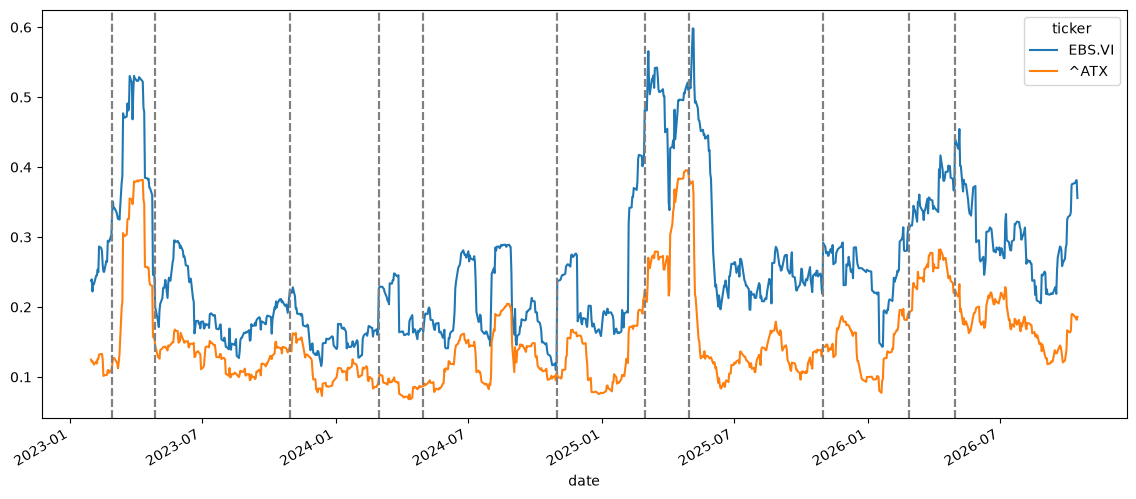

In [397]:
profile = panel.unstack("ticker")
fig, ax = plt.subplots(figsize=(14,6))
ax = profile["vol_20d"].plot(ax=ax)
event_dates = panel[panel["rel_day"]==0].index.get_level_values("date")
for date in event_dates:
    ax.axvline(date,color="gray",ls="--")
plt.show()

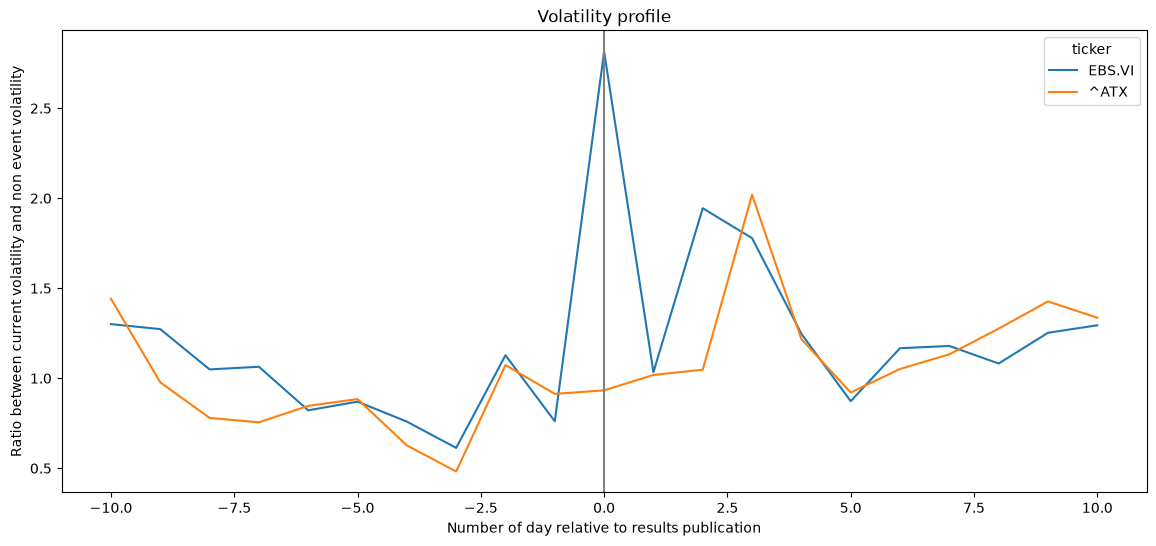

In [398]:
profile = (panel[~panel["event_day_vol_ratio"].isna()].groupby(["ticker","rel_day"])["event_day_vol_ratio"].first()).unstack("ticker")
fig, ax = plt.subplots(figsize=(14,6))
profile.plot(ax=ax)
ax.axvline(x=0,color="gray")
ax.set_xlabel("Number of day relative to results publication")
ax.set_ylabel("Ratio between current volatility and non event volatility")
ax.set_title("Volatility profile")
plt.show()

In [405]:
panel["event_volatility"] = panel.groupby(["ticker", "event_id"])["log_returns"].transform(lambda x: np.sqrt(x**2))
panel["event_volatility_ratio"] = panel["event_volatility"]/panel.index.get_level_values("ticker").map(baseline)
print(panel)

                          open         high          low        close  \
date       ticker                                                       
2023-01-02 EBS.VI    25.201220    25.344266    25.041346    25.327436   
           ^ATX    3126.139893  3166.399902  3126.139893  3159.709961   
2023-01-03 EBS.VI    25.234876    26.160464    25.159146    26.059490   
           ^ATX    3160.310059  3211.350098  3158.199951  3197.939941   
2023-01-04 EBS.VI    26.253022    27.018735    26.084733    26.926176   
...                        ...          ...          ...          ...   
2026-10-13 ^ATX    6599.500000  6660.580078  6593.000000  6627.899902   
2026-10-14 EBS.VI   111.000000   112.000000   110.199997   111.300003   
           ^ATX    6627.899902  6666.779785  6594.750000  6619.120117   
2026-10-15 EBS.VI   109.500000   112.000000   109.099998   109.300003   
           ^ATX    6616.919922  6616.919922  6475.609863  6508.549805   

                    volume  log_returns        gk 

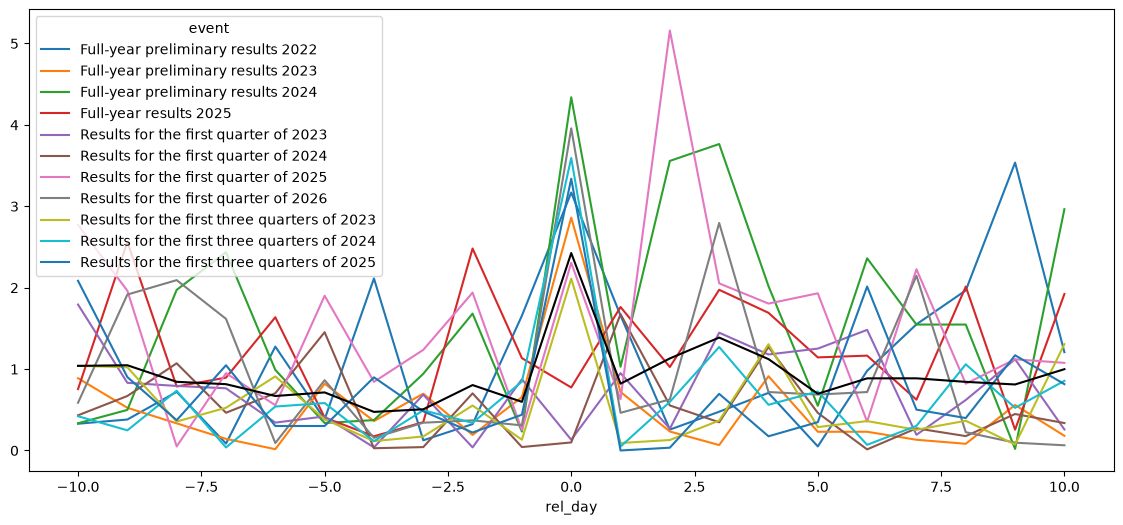

In [439]:
profile = panel[(panel.index.get_level_values("ticker")=="EBS.VI") & (~panel["event_id"].isna())]
profile = profile.pivot(index="rel_day",columns="event",values="event_volatility_ratio")
fig, ax = plt.subplots(figsize=(14,6))
profile.plot(ax=ax)
profile.mean(axis=1).plot(ax=ax,color="black",label="mean")
plt.show()

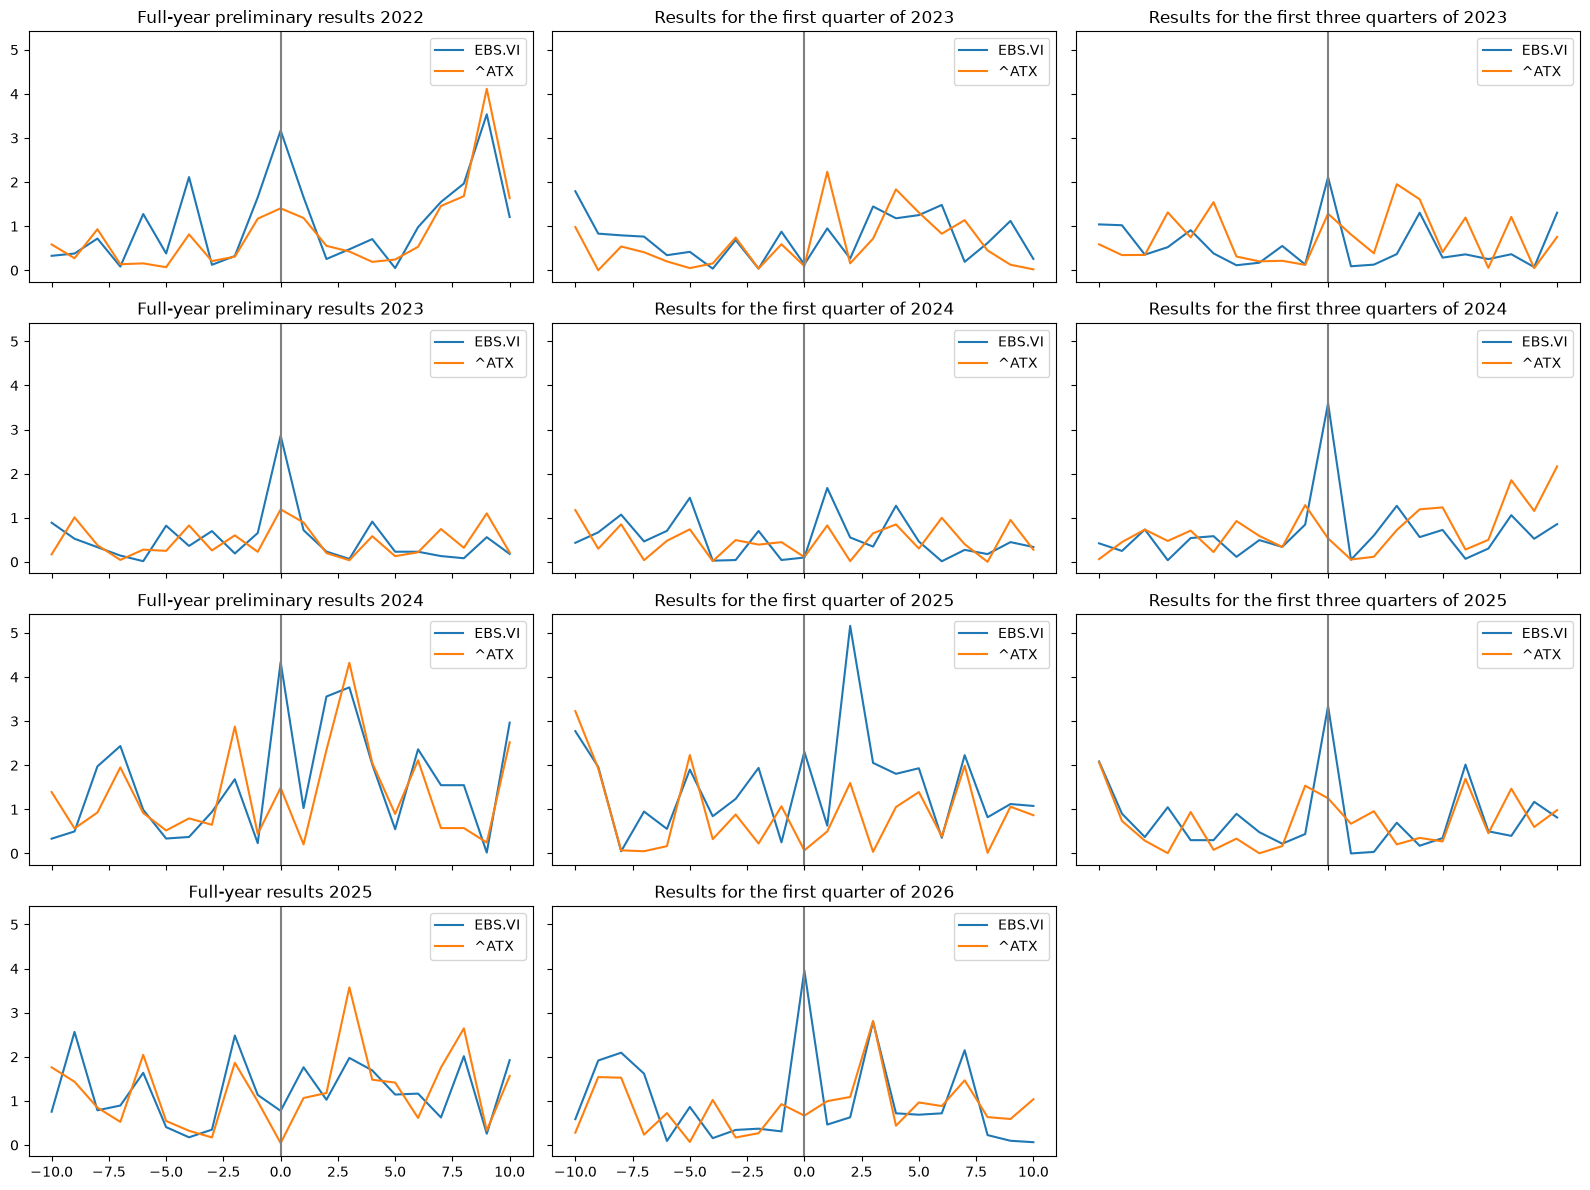

In [ ]:
profile = panel[panel["event_id"].notna()].copy()

events = sorted(profile["event_id"].unique())
fig, axes = plt.subplots(4,3,figsize=(16,12), sharex=True, sharey=True)

for ax, eid in zip(axes.flat,events):
    sub = profile[profile["event_id"]==eid]
    for tkr, grp in sub.groupby(level="ticker"):
        ax.plot(grp["rel_day"],grp["event_volatility_ratio"],label=tkr)
    ax.set_title(grp["event"].iloc[0])
    ax.axvline(0,color="gray")
    ax.legend()
    
for ax in axes.flat[len(events):]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()